# 🧹 Light Cleaning: from `orders.csv` to `sales.csv`

**Zero Grad · Data Analysis course · Pandas**

> 📖 **The lesson (in Arabic), with diagrams and interactive widgets:** [zero-grad.com/courses/da/cleaning](https://zero-grad.com/courses/da/cleaning/)
>
> 🗂️ **The data:** [NileCart Sales on Kaggle](https://www.kaggle.com/datasets/a7madmostafa/nilecart-sales)

This is the solved notebook of the *Light cleaning* lesson.
Every lesson so far used `sales.csv`, a clean table. It was made from the raw `orders.csv`, which has holes, a duplicate,
impossible values and messy text, like every real export. Here we rebuild `sales.csv` from the raw files, one decision at a time.

This is **light** cleaning: the everyday checks an analyst does before any number. Full preprocessing (imputation models,
encoding, scaling) belongs to the machine-learning course.

| # | Part | The question |
|---|---|---|
| 1 | Look first | What's wrong with this table? |
| 2 | Missing values | Drop, fill, or keep? |
| 3 | Duplicates | Is this row here twice? |
| 4 | Types | Is every column the type it should be? |
| 5 | Text | Do equal things look equal? |
| 6 | Impossible values | Which values can't be true? |
| 7 | The pipeline | All of it, in order, with a log |

---
# 0️⃣ Setup

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.figsize"] = (9, 4)
pd.options.display.float_format = "{:,.2f}".format

# On Kaggle the data lives under /kaggle/input, locally in the repo's data/ folder
on_kaggle = sorted(Path("/kaggle/input").glob("**/sales.csv"))
DATA = on_kaggle[0].parent if on_kaggle else Path("../../data")

orders = pd.read_csv(DATA / "orders.csv")
customers = pd.read_csv(DATA / "customers.csv")
products = pd.read_csv(DATA / "products.csv")
governorates = pd.read_csv(DATA / "governorates.csv")
print(orders.shape)

(1501, 8)


---
# 1️⃣ Look first

Never clean blind. The first-look routine from the Pandas basics lesson, on the raw table:

In [2]:
orders.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1501 entries, 0 to 1500
Data columns (total 8 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   order_id     1501 non-null   int64  
 1   order_date   1501 non-null   object 
 2   customer_id  1501 non-null   int64  
 3   product_id   1501 non-null   int64  
 4   quantity     1471 non-null   float64
 5   unit_price   1501 non-null   float64
 6   discount     1461 non-null   float64
 7   status       1491 non-null   object 
dtypes: float64(3), int64(3), object(2)
memory usage: 93.9+ KB


In [3]:
orders.describe().T

,count,mean,std,min,25%,50%,75%,max
order_id,"1,501.00","10,750.00",433.44,"10,001.00","10,375.00","10,750.00","11,125.00","11,500.00"
customer_id,"1,501.00",90.35,62.59,1.00,50.00,85.00,132.00,902.00
product_id,"1,501.00",106.39,2.99,101.00,104.00,106.00,109.00,111.00
quantity,"1,471.00",4.42,13.15,-2.00,2.00,4.00,5.00,500.00
unit_price,"1,501.00","4,922.34","7,597.57",0.00,450.00,"1,140.00","6,825.00","33,600.00"
discount,"1,461.00",0.05,0.07,0.00,0.00,0.00,0.10,0.20


Already three alarms in `describe()`:

* `quantity`: `count` is 1,471, not 1,501 (missing values), the `min` is **−2** and the `max` is **500**.
* `unit_price`: the `min` is **0**.
* `customer_id`: the `max` is 902, but there are 200 customers.

And `info()` says `order_date` is text (`object`). Let's count the missing values properly:

In [4]:
missing = pd.DataFrame({"missing": orders.isna().sum(), "share": orders.isna().mean()})
missing[missing["missing"] > 0]

,missing,share
quantity,30,0.02
discount,40,0.03
status,10,0.01


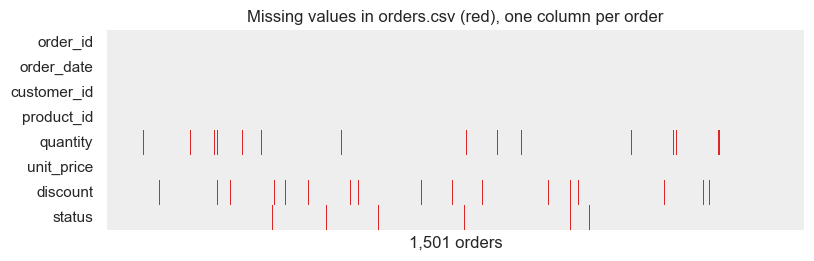

In [5]:
fig, ax = plt.subplots(figsize=(9, 2.6))
sns.heatmap(orders.isna().T, cbar=False, cmap=["#eeeeee", "#dc2626"], xticklabels=False, ax=ax)
ax.set(title="Missing values in orders.csv (red), one column per order", xlabel="1,501 orders")
plt.show()

The red marks are scattered, with no block of rows missing together. Each column needs its own decision.

---
# 2️⃣ Missing values: drop, fill, or keep?

There's no single right answer. Ask, for each column: **what does the hole mean, and what will I compute with this column?**

## 2.1 `quantity` (30 missing): drop the rows

In [6]:
orders.loc[orders["quantity"].isna(), ["order_id", "product_id", "unit_price", "status"]].head()

,order_id,product_id,unit_price,status
41,10147,105,"1,200.00",completed
79,10010,111,63.00,completed
180,10465,110,712.00,completed
183,10263,109,"3,800.00",completed
232,10666,102,"18,900.00",completed


Without a quantity there's no revenue, and there's no honest way to guess how many items someone bought.
What would filling do? Compare the options on the revenue they'd produce:

In [7]:
gross = lambda q: (q * orders["unit_price"]).sum()
q = orders["quantity"].where(orders["quantity"].between(1, 100))       # ignore the impossible values for now
print(f"keep NaN (sum skips it):   {gross(q):>14,.0f}")
print(f"fill with the median ({q.median():.0f}):  {gross(q.fillna(q.median())):>14,.0f}")
print(f"fill with the mean ({q.mean():.2f}): {gross(q.fillna(q.mean())):>14,.0f}")
print(f"fill with 0:               {gross(q.fillna(0)):>14,.0f}")

keep NaN (sum skips it):       29,268,712
fill with the median (4):      30,048,912
fill with the mean (4.09):     30,066,173
fill with 0:                   29,268,712


Filling with the median or the mean invents almost 800,000 EGP of sales that may never have happened
(the mean even invents fractions of a laptop). Filling with 0 gives the right total but a wrong average:

In [8]:
print("mean quantity, NaN skipped: ", round(q.mean(), 2))
print("mean quantity, NaN as 0:    ", round(q.fillna(0).mean(), 2))
print("rows counted by len():      ", len(q), "(NaN or not)")

mean quantity, NaN skipped:  4.09
mean quantity, NaN as 0:     4.0
rows counted by len():       1501 (NaN or not)


Keeping the NaN gives the right total too (`sum()` and `mean()` skip it), but `len()` and every row count still include
30 orders that have no quantity. Dropping them is the clearest choice: 30 of 1,501 lines, 2%.

## 2.2 `discount` (40 missing): fill with 0

Here the hole has a likely meaning: the order system leaves the field empty when there's no discount.
(In a real job, you'd confirm that with whoever owns the system.) And leaving NaN would silently drop
those 40 orders from every revenue sum:

In [9]:
d = orders.dropna(subset=["quantity"]).query("1 <= quantity <= 100 and unit_price > 0")
rev_nan = (d["quantity"] * d["unit_price"] * (1 - d["discount"])).sum()
rev_zero = (d["quantity"] * d["unit_price"] * (1 - d["discount"].fillna(0))).sum()
print(f"discount left NaN: {rev_nan:>14,.0f}")
print(f"discount filled 0: {rev_zero:>14,.0f}   (+{rev_zero - rev_nan:,.0f})")

discount left NaN:     27,273,314
discount filled 0:     27,841,971   (+568,657)


## 2.3 `status` (10 missing): a category of its own

Guessing a status would be inventing facts. Deleting the rows would lose real orders.
Name the gap instead, so it shows up in every count:

In [10]:
orders["status"].fillna("unknown").value_counts()

status
completed    1100
shipped       201
returned      102
cancelled      88
unknown        10
Name: count, dtype: int64

| Column | Missing | Decision | Why |
|---|---|---|---|
| `quantity` | 30 | drop the row | no quantity, no revenue; a guess would invent sales |
| `discount` | 40 | fill 0 | empty means "no discount"; NaN would drop the order from sums |
| `status` | 10 | fill `"unknown"` | keep the order, don't invent a status |

`dropna(subset=[...])`, `fillna(value)`, and `fillna({"col": value})` for several columns at once.

---
# 3️⃣ Duplicates

In [11]:
print("fully duplicated rows:", orders.duplicated().sum())
print("repeated order_id:    ", orders["order_id"].duplicated().sum())
orders[orders.duplicated(keep=False)]

fully duplicated rows: 1
repeated order_id:     1


,order_id,order_date,customer_id,product_id,quantity,unit_price,discount,status
295,10004,2024-01-02,131,111,10.00,57.00,0.00,completed
472,10004,2024-01-02,131,111,10.00,57.00,0.00,completed


Order 10004 is in the file twice, every column identical: an export glitch. `drop_duplicates()` keeps the first copy.

Two different checks:

* `duplicated()`: the **whole row** is repeated. Safe to drop.
* `duplicated(subset=["order_id"])`: the **key** is repeated. If the other columns differ, that's a conflict to investigate, not a row to delete.

Here both find the same single row.

---
# 4️⃣ Types

In [12]:
orders.dtypes

order_id         int64
order_date      object
customer_id      int64
product_id       int64
quantity       float64
unit_price     float64
discount       float64
status          object
dtype: object

## 4.1 Dates: `pd.to_datetime`

In [13]:
orders["order_date"] = pd.to_datetime(orders["order_date"])
print(orders["order_date"].dtype, orders["order_date"].min(), orders["order_date"].max())

datetime64[ns] 2024-01-01 00:00:00 2031-03-15 00:00:00


The last date is in **2031**. The type is right now, and that's what lets us see the impossible value: the next part.

When a column has values that can't be parsed, `errors="coerce"` turns them into `NaT` (a missing date) instead of failing:

In [14]:
pd.to_datetime(pd.Series(["2025-11-28", "28/11/2025", "soon"]), errors="coerce", format="%Y-%m-%d")

0   2025-11-28
1          NaT
2          NaT
dtype: datetime64[ns]

## 4.2 Numbers stored as text: `pd.to_numeric`

Not in NileCart, but in almost every Excel export:

In [15]:
raw = pd.Series(["1,200", "450", "n/a", "3,800"])
print(raw.dtype)
pd.to_numeric(raw.str.replace(",", ""), errors="coerce")

object


0   1,200.00
1     450.00
2        NaN
3   3,800.00
dtype: float64

## 4.3 `quantity` back to whole numbers, `status` as a category

`quantity` is `float64` only because of the NaN (the NumPy lesson). Once the missing rows are gone it can be an integer.
A text column with a few repeated values can be a `category`: same values, much less memory.

In [16]:
before = orders["status"].memory_usage(deep=True)
after = orders["status"].fillna("unknown").astype("category").memory_usage(deep=True)
print(f"status as text:     {before:>8,} bytes")
print(f"status as category: {after:>8,} bytes")

status as text:       86,426 bytes
status as category:    2,090 bytes


---
# 5️⃣ Text: do equal things look equal?

In [17]:
print(customers["name"].head(3).map(repr).tolist())
print(sorted(customers["governorate"].unique(), key=str.lower)[:6])
print(customers["email"].iloc[5:9].tolist())

["'  MONA MOSTAFA '", "'  DINA FAROUK '", "'  LAILA ABDELRAHMAN '"]
[' alexandria', 'Alexandria', 'Assiut', 'Aswan', 'Beheira', 'cairo']
['REEM.ELSAYED6@EXAMPLE.COM', 'MONA.SALEH7@EXAMPLE.COM', 'LAILA.FAROUK8@EXAMPLE.COM', 'OMAR.ELSAYED9@EXAMPLE.COM']


Extra spaces, capitals, mixed case: a human reads `" alexandria"` and `"Alexandria"` as the same place, Pandas doesn't.
That's what broke the merge in the previous lesson. The `.str` tools fix a whole column at once:

In [18]:
print("governorates before:", customers["governorate"].nunique())
customers["governorate"] = customers["governorate"].str.strip().str.title()
customers["name"] = customers["name"].str.strip().str.title()
customers["email"] = customers["email"].str.strip().str.lower()
print("governorates after: ", customers["governorate"].nunique())
print("all of them in governorates.csv:", customers["governorate"].isin(governorates["governorate"]).all())

governorates before: 19
governorates after:  16
all of them in governorates.csv: True


| Tool | Does |
|---|---|
| `.str.strip()` | removes spaces at both ends |
| `.str.lower()` / `.str.title()` | one casing for everyone |
| `.str.replace(a, b)` | swap characters (`","` in numbers) |
| `.str.contains(...)` | find the values that look suspicious |

---
# 6️⃣ Impossible values

The statistics lesson said: **an outlier is a question, not an error.** Here are the ones whose answer is "error".
They aren't found by an outlier rule but by **business rules**, things that can't be true:

In [19]:
rules = {
    "quantity <= 0":       orders["quantity"] <= 0,
    "quantity > 100":      orders["quantity"] > 100,
    "unit_price <= 0":     orders["unit_price"] <= 0,
    "order_date > 2025":   orders["order_date"] > "2025-12-31",
}
for name, m in rules.items():
    print(f"{name:18} {m.sum()} row(s)")
bad = pd.concat(rules, axis=1).any(axis=1)
orders.loc[bad, ["order_id", "order_date", "product_id", "quantity", "unit_price", "status"]]

quantity <= 0      1 row(s)
quantity > 100     1 row(s)
unit_price <= 0    1 row(s)
order_date > 2025  1 row(s)


,order_id,order_date,product_id,quantity,unit_price,status
719,10008,2024-01-05,106,-2.00,450.00,shipped
979,11201,2031-03-15,106,1.00,472.00,shipped
1005,10901,2025-04-24,111,5.00,0.00,completed
1478,10251,2024-06-18,101,500.00,"32,000.00",completed


* A quantity of −2, and 500 laptops in one line (product 101 is the Laptop, 32,000 EGP each).
* A free item, on an order whose customer doesn't exist either.
* An order in 2031.

How much would the 500-laptop line alone add to the revenue if nobody looked?

In [20]:
big = orders.loc[orders["quantity"] > 100].iloc[0]
print(f"{big['quantity']:.0f} x {big['unit_price']:,.0f} = {big['quantity'] * big['unit_price']:,.0f} EGP")

500 x 32,000 = 16,000,000 EGP


More than half of NileCart's real revenue for the two years, from one typo. We drop these 4 rows.

## 6.1 Questions without an answer yet

Some checks find things that may be wrong, but can't be fixed by the analyst alone:

In [21]:
orphans = ~orders["customer_id"].isin(customers["customer_id"])
print("orders whose customer doesn't exist:", orphans.sum())

customers["signup_date"] = pd.to_datetime(customers["signup_date"])
first_order = orders.groupby("customer_id")["order_date"].min()
early = customers.set_index("customer_id").join(first_order)
print("customers whose first order is before their sign-up:", (early["order_date"] < early["signup_date"]).sum())

orders whose customer doesn't exist: 3
customers whose first order is before their sign-up: 50


50 customers ordered before they signed up. Maybe `signup_date` is when they created an *online* account, maybe it's a bug.
That's a question for the business, written in the cleaning log, not a row to delete.
We keep the orphan orders too, with `"Unknown"` for the customer: the sale happened.

---
# 7️⃣ The pipeline

Every decision above, in order, as one function. Each step logs how many rows it removed.

In [22]:
def clean_orders(raw):
    log = [("raw orders.csv", len(raw))]
    df = raw.copy()
    df["order_date"] = pd.to_datetime(df["order_date"])

    bad = ((df["quantity"] <= 0) | (df["quantity"] > 100) |
           (df["unit_price"] <= 0) | (df["order_date"] > "2025-12-31"))
    df = df.loc[~bad];                               log.append(("drop impossible values", len(df)))
    df = df.drop_duplicates();                       log.append(("drop the duplicated row", len(df)))
    df = df.dropna(subset=["quantity"]);             log.append(("drop missing quantity", len(df)))
    df = df.fillna({"discount": 0, "status": "unknown"})
    df["quantity"] = df["quantity"].astype(int)
    return df, pd.DataFrame(log, columns=["step", "rows"])

clean, log = clean_orders(pd.read_csv(DATA / "orders.csv"))
log["removed"] = -log["rows"].diff().fillna(0).astype(int)
log

,step,rows,removed
0,raw orders.csv,1501,0
1,drop impossible values,1497,4
2,drop the duplicated row,1496,1
3,drop missing quantity,1466,30


Then the merges from the previous lesson, with the cleaned customers, and the derived columns:

In [23]:
s = (clean
     .merge(customers[["customer_id", "name", "governorate", "segment"]], on="customer_id", how="left", validate="many_to_one")
     .merge(governorates[["governorate", "region"]], on="governorate", how="left", validate="many_to_one")
     .merge(products[["product_id", "product_name", "category", "unit_cost"]], on="product_id", how="left", validate="many_to_one"))
s[["name", "governorate", "segment", "region"]] = s[["name", "governorate", "segment", "region"]].fillna("Unknown")
s["gross"] = (s["quantity"] * s["unit_price"]).round(2)
s["revenue"] = (s["gross"] * (1 - s["discount"])).round(2)
s["profit"] = (s["revenue"] - s["quantity"] * s["unit_cost"]).round(2)
s = s.sort_values("order_date").reset_index(drop=True)
print(s.shape)

(1466, 18)


## 7.1 Did we get `sales.csv` back?

In [24]:
sales = pd.read_csv(DATA / "sales.csv", parse_dates=["order_date"])
cols = sales.columns
mine = s[cols].sort_values("order_id").reset_index(drop=True)
theirs = sales.sort_values("order_id").reset_index(drop=True)
pd.testing.assert_frame_equal(mine, theirs, check_dtype=False)
print("identical:", mine.shape)

identical: (1466, 18)


Same 1,466 rows, same values. Every table of this course came out of these few decisions.

## 7.2 The cleaning log

Write down what you did and why, next to the data. It's what lets someone else (or you, in three months) trust the numbers.

| Step | Rows | Decision |
|---|---|---|
| raw `orders.csv` | 1,501 | |
| impossible values | −4 | quantity −2 and 500, price 0, a date in 2031 |
| duplicates | −1 | order 10004 was in the file twice |
| missing quantity | −30 | no quantity, no revenue |
| missing discount | 0 | filled 0 (empty means no discount) |
| missing status | 0 | filled `"unknown"` |
| text | 0 | names and governorates stripped and title-cased, emails lower-cased |
| open questions | | 3 orders with no customer (kept as "Unknown"); 50 customers ordered before signing up |
| **`sales.csv`** | **1,466** | |

---
# 🧰 Summary

| Problem | Find it | Fix it |
|---|---|---|
| Missing values | `isna().sum()`, `isna().mean()` | `dropna(subset=)`, `fillna({...})`, or a named category |
| Duplicates | `duplicated()`, `duplicated(subset=["id"])` | `drop_duplicates()` |
| Wrong types | `info()`, `dtypes` | `pd.to_datetime`, `pd.to_numeric(errors="coerce")`, `astype` |
| Messy text | `unique()`, `nunique()` | `.str.strip()`, `.str.title()`, `.str.lower()` |
| Impossible values | `describe()`, business rules | drop (or fix, if you know the right value) |
| Doubtful values | consistency checks | ask, and write it in the log |

* Look before you clean, and decide column by column.
* NaN silently drops out of sums; filling invents data. Both are choices: make them on purpose.
* An outlier is a question; an impossible value is an error.
* Put the steps in one function, log the row count after each, and write down why.

**Next part of the course:** Visualization: why we draw, and how to pick the chart.

📚 All the lessons of the course: [zero-grad.com/courses/da](https://zero-grad.com/courses/da/)